In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
import pandas as pd
from matplotlib.ticker import MaxNLocator
import matplotlib.cm as cm
import matplotlib.ticker as ticker


In [2]:


file_name = np.array([
    "R134a_emimtfsi_160_480_215",
    "R134a_emimtfsi_320_320_422",
    "R134a_emimtfsi_598_256_573",
    "R134a_emimtfsi_1088_192_646",
    "R134a_emimtfsi_1294_128_656",
    "R32_emimtfsi_160_480_293",
    "R32_emimtfsi_320_320_721",
    "R32_emimtfsi_598_256_1171",
    "R32_emimtfsi_1088_192_1512",
    "R32_emimtfsi_2048_86_1653"
])


hfc_array = np.array([
    "HFC-134a", "HFC-134a", "HFC-134a", "HFC-134a", "HFC-134a", 
    "HFC-32", "HFC-32", "HFC-32", "HFC-32", "HFC-32"
])


title_labels = np.array([
    "$x_{HFC-134a}$ = 0.25", "$x_{HFC-134a}$ = 0.50", "$x_{HFC-134a}$ = 0.70", 
    "$x_{HFC-134a}$ = 0.85", "$x_{HFC-134a}$ = 0.91", "$x_{HFC-32}$ = 0.25", 
    "$x_{HFC-32}$ = 0.50", "$x_{HFC-32}$ = 0.70", "$x_{HFC-32}$ = 0.85", 
    "$x_{HFC-32}$ = 0.96"
])


save_fig_labels = np.array([
    "25_R134a_n", "50_R134a_n", "70_R134a_n", "85_R134a_n", "91_R134a_n", 
    "25_R32_n", "50_R32_n", "70_R32_n", "85_R32_n", "96_R32_n"
])


In [3]:
def RDF_HFC_IL(file_id, hfc, title_label):    #    hfc = "R134a"   R134a_emimtfsi_1088_192_646_Diff_RDF_1.json
    openfile = open(f"{file_id}_Diff_RDF_1.json")
    dictionary = json.load(openfile)
    dict_items = dictionary.items()
    list_dictionary = list(dict_items)
    RDF_data = (((list_dictionary[3][1])))
    RDF_data = list(RDF_data.items())

    Radial_dist_emim_emim = RDF_data[0][1]
    Radial_dist_emim_tfsi = RDF_data[1][1]
    Radial_dist_hfc_emim = RDF_data[2][1]
    Radial_dist_hfc_hfc = RDF_data[3][1]
    Radial_dist_hfc_tfsi = RDF_data[4][1]
    Radial_dist_tfsi_tfsi = RDF_data[5][1]
    distance = RDF_data[6][1]

    Radial_dist_all = np.array([Radial_dist_emim_emim, Radial_dist_emim_tfsi, 
               Radial_dist_hfc_emim, Radial_dist_hfc_hfc,
               Radial_dist_hfc_tfsi, Radial_dist_tfsi_tfsi])

    rdf_labels = np.array(["EMIM-EMIM",
    "EMIM-TFSI",
    f"{hfc}-EMIM",
    f"{hfc}-{hfc}",
    f"{hfc}-TFSI",
    "TFSI-TFSI"])
    
    
    fig, ax = plt.subplots()
    
    for i in range(len(Radial_dist_all)):
        ax.plot(distance, Radial_dist_all[i], label = rdf_labels[i])
        plt.title(f"{title_label}")

    plt.legend()
    plt.yticks(fontsize=16)
    plt.xticks(fontsize=16)
    ax.minorticks_on()
    plt.xlabel(r' r $(\AA) $', fontsize=20)
    plt.ylabel(r'$ g(r) $', fontsize=20)
    plt.show()
    
    return plt.show()


In [4]:

# for i in range(len(file_name)):
#     print(i)
#     RDF_HFC_IL(file_name[i], hfc_array[i], title_labels[i])
    

In [5]:
def Get_cation_anion_RDF(file_id, hfc):    #    hfc = "R134a"   R134a_emimtfsi_1088_192_646_Diff_RDF_1.json
    openfile = open(f"{file_id}_Diff_RDF_1.json")
    dictionary = json.load(openfile)
    dict_items = dictionary.items()
    list_dictionary = list(dict_items)
    RDF_data = (((list_dictionary[3][1])))
    RDF_data = list(RDF_data.items())

    Radial_dist_emim_tfsi = RDF_data[1][1]
    Radial_dist_hfc_emim = RDF_data[2][1]
    Radial_dist_hfc_hfc = RDF_data[3][1]
    Radial_dist_hfc_tfsi = RDF_data[4][1]

    distance = RDF_data[6][1]
    
    return distance, Radial_dist_emim_tfsi
    

In [6]:
def RDF_HFC_IL_reduced(file_id, hfc, title_label, show_legend, savefig_labels, ax, is_last):    #    hfc = "R134a"   R134a_emimtfsi_1088_192_646_Diff_RDF_1.json
    openfile = open(f"{file_id}_Diff_RDF_1.json")
    dictionary = json.load(openfile)
    dict_items = dictionary.items()
    list_dictionary = list(dict_items)
    RDF_data = (((list_dictionary[3][1])))
    RDF_data = list(RDF_data.items())

    Radial_dist_emim_tfsi = RDF_data[1][1]
    Radial_dist_hfc_emim = RDF_data[2][1]
    Radial_dist_hfc_hfc = RDF_data[3][1]
    Radial_dist_hfc_tfsi = RDF_data[4][1]
    Radial_dist_tfsi_hfc = RDF_data[4][1]

    distance = RDF_data[6][1]

    Radial_dist_all = np.array([Radial_dist_emim_tfsi, 
               Radial_dist_hfc_emim, Radial_dist_hfc_hfc,
               Radial_dist_hfc_tfsi, Radial_dist_tfsi_hfc])
     #, Radial_dist_tfsi_hfc
    rdf_labels = np.array(["$[C_2C_1im]^+$ around $[TFSI]^-$",
    f"{hfc} around $[C_2C_1im]^+$",
    f"{hfc} around {hfc}",
    f"{hfc} around $[TFSI]^-$",
    f"$[TFSI]^-$  around {hfc}"])
    
    #fig, ax = plt.subplots()
    
    # Plot on the passed 'ax' instead of creating a new one
    for i in range(len(Radial_dist_all[0:-1])):
        ax.plot(distance, Radial_dist_all[i], label=rdf_labels[i])
        
        # Corner text
        ax.text(0.95, 0.05, title_label, transform=ax.transAxes, 
                fontsize=20, ha='right', va='bottom',
                bbox=dict(facecolor='white', alpha=0.5, edgecolor='none'))
    
        # Formatting
        if show_legend:
            ax.legend(loc='upper right')
            
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(labelsize=16)
        ax.minorticks_on()
        ax.set_ylabel(r'$ g(r) $', fontsize=20)
        
        # Only show x-axis label and ticks on the bottom plot
        if is_last:
            ax.set_xlabel(r' r $(\AA) $', fontsize=20)
        else:
            # Hide x-axis labels for internal plots
            ax.tick_params(labelbottom=False)

        
    
    return Radial_dist_all, distance

    

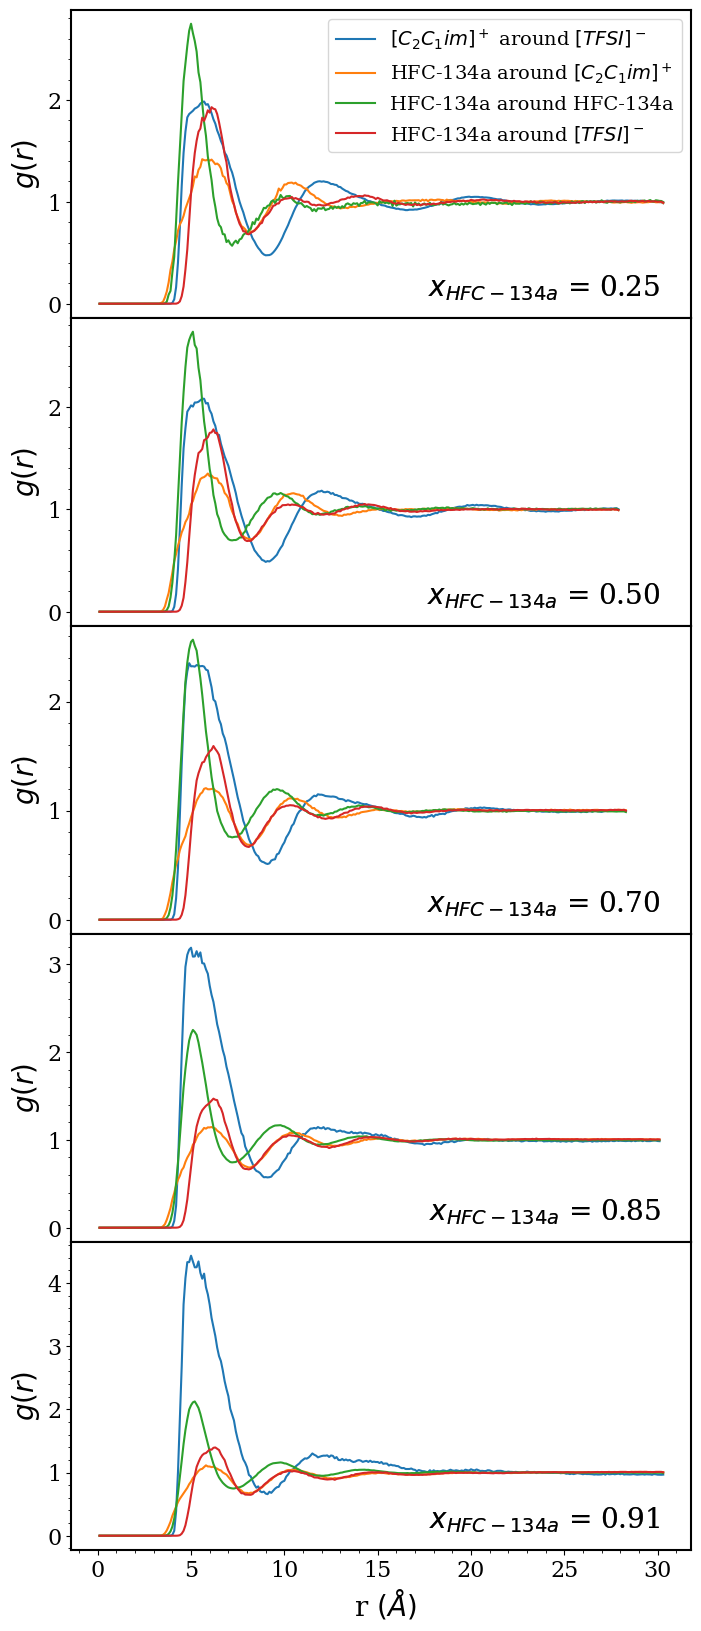

In [7]:

plt.rcParams.update({
    "text.usetex": False, # Set to True if you have LaTeX installed
    "font.family": "serif",
    "font.size": 14,
    "axes.linewidth": 1.5
})

rdf_all = []
distance_all = []
start = 0
stop = 5
plots_len = int(stop - start)

# Create the figure once
fig, axes = plt.subplots(plots_len, 1, figsize=(8, 4 * plots_len), sharex=True)
plt.subplots_adjust(hspace=0) # Removes vertical space between plots

RDF_R134a = []
Dist_R134a = []

for i, name in enumerate(file_name[start:stop]):
    # Determine if this is the last plot to show the x-label
    is_last = (i == plots_len - 1)
    
    # Pass the specific axis from our grid into the function
    RDF_R134a_i = RDF_HFC_IL_reduced(name, hfc_array[i+start], title_labels[i+start], 
                       (i == 0), save_fig_labels[i+start], axes[i], is_last)
    RDF_R134a.append(RDF_R134a_i[0])
    Dist_R134a.append(RDF_R134a_i[1])

#plt.savefig("RDF_Plots_R134a.png", dpi=300, bbox_inches='tight')


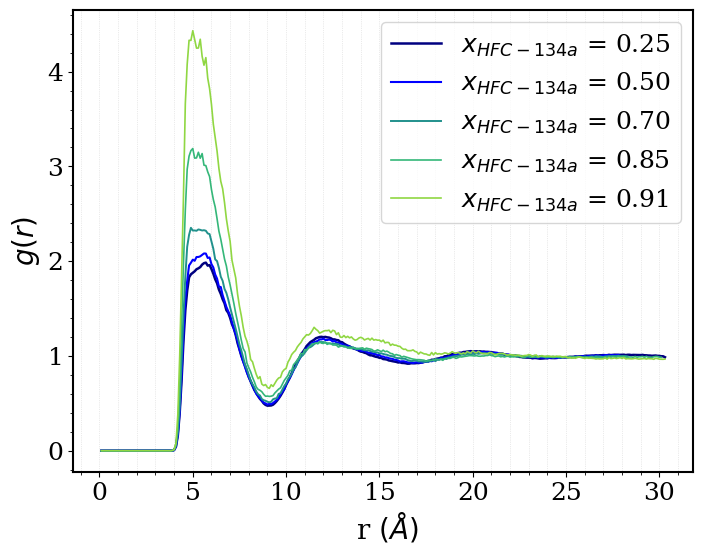

In [52]:


plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


colors = [
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
]


legends_ = [ '$x_{HFC-134a}$ = 0.25' , '$x_{HFC-134a}$ = 0.50', '$x_{HFC-134a}$ = 0.70',
          '$x_{HFC-134a}$ = 0.85', '$x_{HFC-134a}$ = 0.91' ]

linewidth = [1.8, 1.5, 1.4, 1.2, 1.2]

start = 0
stop = 5

fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i, name in enumerate(file_name[start:stop]):
    CatAn_RDF = (Get_cation_anion_RDF(name, "R134a"))[1]
    CatAn_dist = (Get_cation_anion_RDF(name, "R134a"))[0]
    ax.plot(CatAn_dist, CatAn_RDF, color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)

# Legend and Labels
ax.legend()
ax.set_xlabel(r' r $(\AA) $', fontsize=20) 
ax.set_ylabel(r'$ g(r) $', fontsize=20)

plt.savefig(f"R134a_emimtfsi_RDF_ILIL", dpi=300, bbox_inches='tight')
#plt.show()



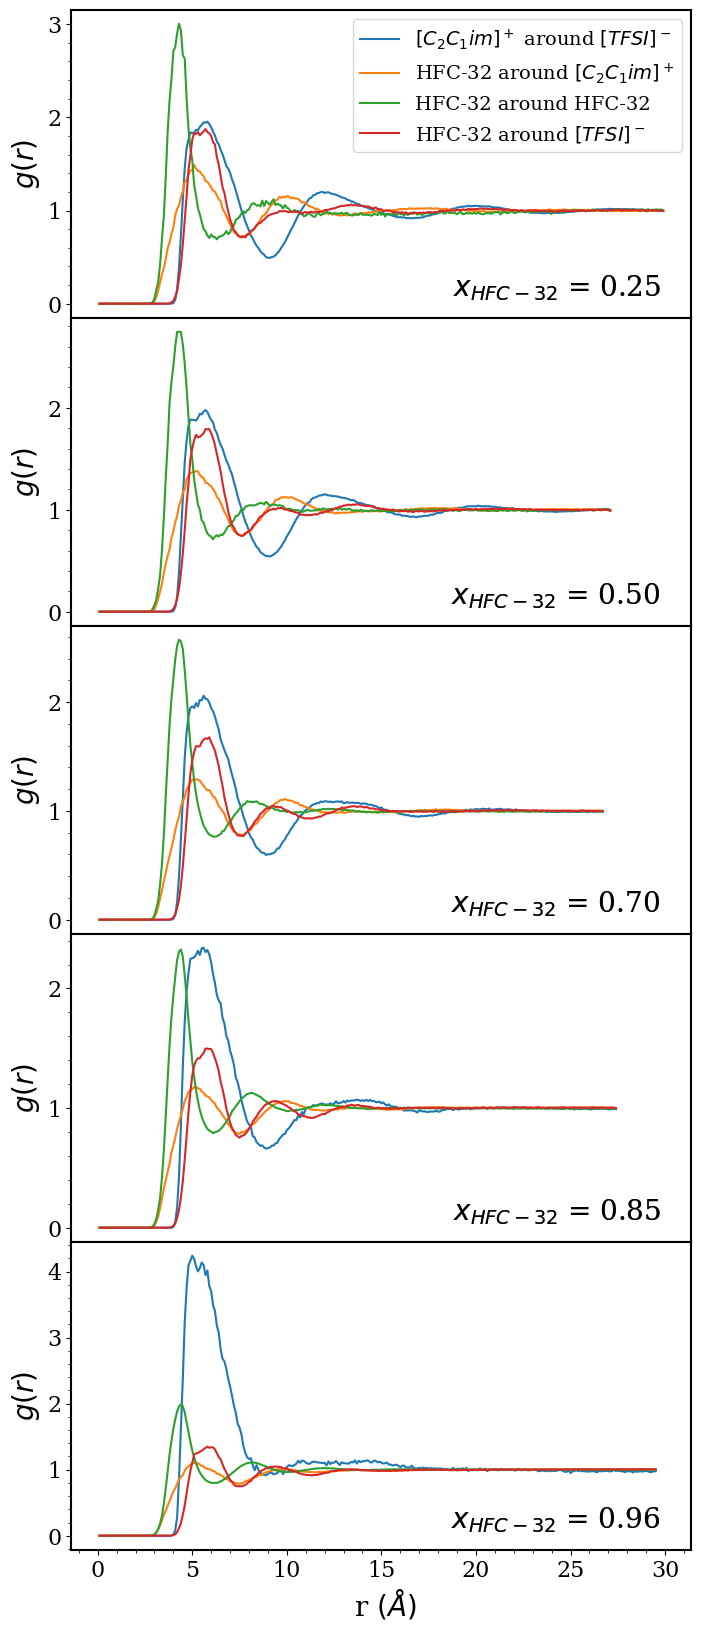

In [8]:
plt.rcParams.update({
    "text.usetex": False, # Set to True if you have LaTeX installed
    "font.family": "serif",
    "font.size": 14,
    "axes.linewidth": 1.5
})

rdf_all = []
distance_all = []
start = 5
stop = len(file_name)
plots_len = int(stop - start)

# Create the figure once
fig, axes = plt.subplots(plots_len, 1, figsize=(8, 4 * plots_len), sharex=True)
plt.subplots_adjust(hspace=0) # Removes vertical space between plots

RDF_R32 = []
Dist_R32 = []

for i, name in enumerate(file_name[start:stop]):
    # Determine if this is the last plot to show the x-label
    is_last = (i == plots_len - 1)
    
    # Pass the specific axis from our grid into the function
    RDF_R32_i = RDF_HFC_IL_reduced(name, hfc_array[i+start], title_labels[i+start], 
                       (i == 0), save_fig_labels[i+start], axes[i], is_last)
    RDF_R32.append(RDF_R32_i[0])
    Dist_R32.append(RDF_R32_i[1])

#plt.savefig("RDF_Plots_R32.png", dpi=300, bbox_inches='tight')
        

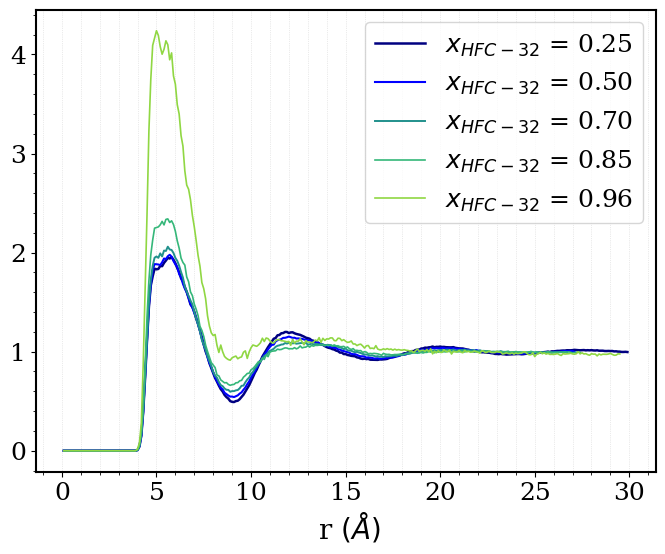

In [55]:


plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


colors = [
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
]


legends_ = [ '$x_{HFC-32}$ = 0.25' , '$x_{HFC-32}$ = 0.50', '$x_{HFC-32}$ = 0.70',
          '$x_{HFC-32}$ = 0.85', '$x_{HFC-32}$ = 0.96' ]

linewidth = [1.8, 1.5, 1.4, 1.2, 1.2]

start = 5
stop = len(file_name)

fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i, name in enumerate(file_name[start:stop]):
    CatAn_RDF = (Get_cation_anion_RDF(name, "R32"))[1]
    CatAn_dist = (Get_cation_anion_RDF(name, "R32"))[0]
    ax.plot(CatAn_dist, CatAn_RDF, color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)

# Legend and Labels
ax.legend()
ax.set_xlabel(r' r $(\AA) $', fontsize=20) 
#ax.set_ylabel(r'$ g(r) $', fontsize=20)

plt.savefig(f"R32_emimtfsi_RDF_ILIL", dpi=300, bbox_inches='tight')
#plt.show()



In [115]:
def find_RDF_minima(distance, RDF):
    ref_points = []
    for i in range(len(RDF)-1):
        if i == 0:
            continue
        else:
            if RDF[i] >= 1 and RDF[i-1] < 1:
                ref_points.append(i)
    start_index = ref_points[0]
    stop_index = ref_points[2]
    RDF_array = RDF[start_index:stop_index]
    first_minima = min(RDF_array)
    first_minima_index = np.where(RDF == first_minima)[0] #np.argmin(RDF[start_index:stop_index]) #RDF.index(first_minima)
    first_minima_index = int(first_minima_index[0])
    minima_pos = distance[first_minima_index]
    return minima_pos, first_minima, first_minima_index, ref_points


In [118]:
num_rdf = 5

start = 0
stop = 5
#stop = len(file_name)
rdf_comps = int(stop - start)


R134a_rdf_minima = np.zeros([rdf_comps, num_rdf])
R134a_dist_minima = np.zeros([rdf_comps, num_rdf])
R134a_index_minima = np.zeros([rdf_comps, num_rdf])

rdf_all = RDF_R134a
distance_all = Dist_R134a

for i in range(rdf_comps):
    for j in range(num_rdf):
        rdf_ = rdf_all[i][j]
        distance_ = distance_all[i]
        minima_ = find_RDF_minima(distance_, rdf_)
        R134a_dist_minima[i,j] = minima_[0]
        R134a_rdf_minima[i,j] = minima_[1]
        R134a_index_minima[i,j] = minima_[2]
        
print(R134a_rdf_minima)
print()
print(R134a_dist_minima)        
        

[[0.47516998 0.69853728 0.56864258 0.68110163 0.68110163]
 [0.48677773 0.70671318 0.69678611 0.69046403 0.69046403]
 [0.5109319  0.68428934 0.7547802  0.66691247 0.66691247]
 [0.57306339 0.68537829 0.74395787 0.66368399 0.66368399]
 [0.65787987 0.67052663 0.74669697 0.64740155 0.64740155]]

[[9.  8.1 7.2 8.1 8.1]
 [9.  8.3 7.2 8.  8. ]
 [9.1 8.3 7.2 8.1 8.1]
 [9.1 8.1 7.2 8.1 8.1]
 [9.1 8.1 7.3 8.2 8.2]]


In [119]:
# Radial_dist_emim_tfsi = RDF_data[1][1]
# Radial_dist_hfc_emim = RDF_data[2][1]
# Radial_dist_hfc_hfc = RDF_data[3][1]
# Radial_dist_hfc_tfsi = RDF_data[4][1]
# Radial_dist_tfsi_hfc = RDF_data[4][1]

In [121]:

num_rdf = 5

start = 5
stop = len(file_name)
#stop = len(file_name)
rdf_comps = int(stop - start)


R32_rdf_minima = np.zeros([rdf_comps, num_rdf])
R32_dist_minima = np.zeros([rdf_comps, num_rdf])
R32_index_minima = np.zeros([rdf_comps, num_rdf])

rdf_all = RDF_R32
distance_all = Dist_R32

for i in range(rdf_comps):
    for j in range(num_rdf):
        #print(file_name[start+i])
        rdf_ = rdf_all[i][j]
        distance_ = distance_all[i]
        minima_ = find_RDF_minima(distance_, rdf_)
        R32_dist_minima[i,j] = minima_[0]
        R32_rdf_minima[i,j] = minima_[1]
        R32_index_minima[i,j] = minima_[2]
        
print(R32_rdf_minima)
print()
print(R32_dist_minima)        
        


[[0.49150773 0.71159681 0.69032432 0.71123315 0.71123315]
 [0.54137725 0.74656762 0.71057519 0.74246    0.74246   ]
 [0.59514295 0.77650842 0.76340905 0.76906798 0.76906798]
 [0.66026886 0.78532125 0.79048048 0.7520265  0.7520265 ]
 [0.91398032 0.78531142 0.79877695 0.74795283 0.74795283]]

[[9.1 7.8 6.3 7.6 7.6]
 [9.1 7.7 6.1 7.6 7.6]
 [8.9 7.6 6.2 7.7 7.7]
 [8.9 7.5 6.1 7.5 7.5]
 [8.9 7.5 6.3 7.6 7.6]]


In [13]:
def CN_HFC_IL(file_id_array, pairs_id, cut_off_distance_array):    #    hfc = "R134a"   R134a_emimtfsi_1088_192_646_Diff_RDF_1.json
    CN_data_name_2Darray = []
    #CN_data_firstminima_2Darray = []
    CN_data_integral_3Darray = []
    
    for j in range(len(file_id_array)):
        openfile = open(f"{file_id_array[j]}_Diff_RDF_1.json")
        dictionary = json.load(openfile)
        dict_items = dictionary.items()
        list_dictionary = list(dict_items)
        CN_data_all = list((list_dictionary[0][1]).items())
    
        CN_data_name_array = []
        #CN_data_firstminima_array = []
        CN_data_integral_array = []
        for i in pairs_id:
            CN_data_name = CN_data_all[i][0]
            CN_data_name_array.append(CN_data_name)
            CN_data_main = list((CN_data_all[i][1]).items())
            #CN_data_firstminima = CN_data_main[2][1][0]
            #CN_data_firstminima_array.append(CN_data_firstminima)
            CN_data_integral = CN_data_main[1][1]
            CN_data_integral_array.append(CN_data_integral)
    
        CN_data_name_2Darray.append(CN_data_name_array)
        #CN_data_firstminima_2Darray.append(CN_data_firstminima_array)
        CN_data_integral_3Darray.append(CN_data_integral_array)
    
    
    CN_data_name_2Darray = np.array(CN_data_name_2Darray, dtype=object)
    #CN_data_firstminima_2Darray = np.array(CN_data_firstminima_2Darray, dtype=object)
    CN_data_integral_3Darray = np.array(CN_data_integral_3Darray, dtype=object)
    
    #max_minima = np.amax(CN_data_firstminima_2Darray.astype(float))
    #max_minima_pos = np.argmax(CN_data_firstminima_2Darray.astype(float))

    CN_value_2D_array = np.empty((len(file_id_array), len(pairs_id)))
    for k in range(len(file_id_array)):
        for l in range(len(pairs_id)):
            cut_off_distance = cut_off_distance_array[k,l]
            index_cumulintegral = int(cut_off_distance/0.1 - 1)
            CN_array = CN_data_integral_3Darray[k, l]
            CN_value = CN_array[index_cumulintegral]
            CN_value_2D_array[k, l] = CN_value

    return CN_data_name_2Darray, CN_value_2D_array


In [14]:

file_name_R32_o = np.array(["R32_emimtfsi_2048_86_1653",
"R32_emimtfsi_1088_192_1512",
"R32_emimtfsi_598_256_1171",
"R32_emimtfsi_320_320_721",
"R32_emimtfsi_160_480_293"])
file_name_R32 = file_name_R32_o[::-1]



file_name_R134a_o = np.array([
"R134a_emimtfsi_1294_128_656",
"R134a_emimtfsi_1088_192_646",
"R134a_emimtfsi_598_256_573",
"R134a_emimtfsi_320_320_422",
"R134a_emimtfsi_160_480_215"])
file_name_R134a = file_name_R134a_o[::-1]

pairs_id = [2, 3, 4, 5, 7] 
comp_array_R32_o = [0.96, 0.85, 0.70, 0.50, 0.25]
comp_array_R32 = comp_array_R32_o[::-1]
comp_array_R134a_o = [0.91, 0.85, 0.70, 0.50, 0.25]
comp_array_R134a = comp_array_R134a_o[::-1]


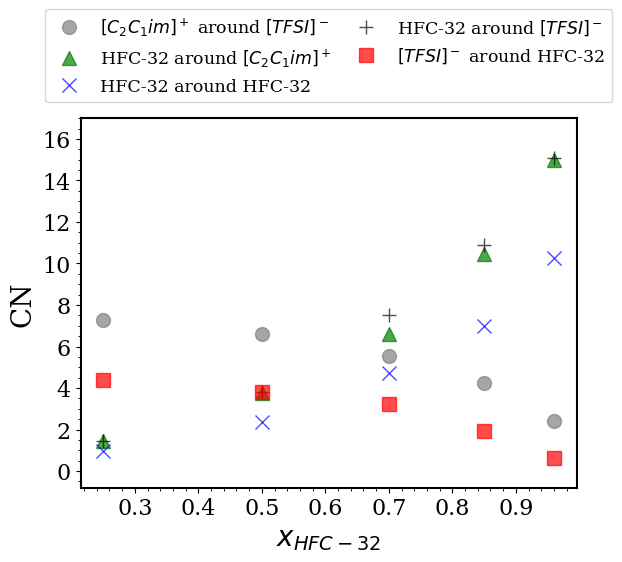

In [16]:

CN_R32_all = CN_HFC_IL(file_name_R32, pairs_id, R32_dist_minima)
CN_R32 = CN_R32_all[-1]
CN_R32_names = CN_R32_all[0][0,:]


replacements = {
    "EMIM": "$[C_2C_1im]^+$",
    "TFSI": "$[TFSI]^-$",
    "R32": "HFC-32",
    "R134a": "HFC-134a"
}


def format_label(label):
    for old, new in replacements.items():
        label = label.replace(old, new)
    return label

CN_R32_names = np.array([format_label(name) for name in CN_R32_names])


markers_id = [ 'o', '^', 'x', '+', 's']
color_id = [ 'gray', 'green', 'blue', 'black', 'red']





fig, ax = plt.subplots()
for p in range(len(CN_R32_names)):
    #print(CN_R32_names[p])
    plt.plot(comp_array_R32, CN_R32[:,p], label=f'{CN_R32_names[p]}', marker=markers_id[p], \
             linestyle='', markersize=10, alpha=0.7, color=color_id[p])
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.18, 0.3), loc="lower left", mode="expand", ncol=2, fontsize=12.5)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
ax.minorticks_on()
plt.ylim(-0.8, 17)
plt.xlabel(r'$x_{HFC-32}$', fontsize=20)
plt.ylabel(f'CN', fontsize=20)
#plt.title()
#plt.show()
plt.savefig(f"R32_emimtfsi_CN_n", dpi=300, bbox_inches='tight')


In [17]:
print(CN_R32_names)

['$[C_2C_1im]^+$ around $[TFSI]^-$' 'HFC-32 around $[C_2C_1im]^+$'
 'HFC-32 around HFC-32' 'HFC-32 around $[TFSI]^-$'
 '$[TFSI]^-$ around HFC-32']


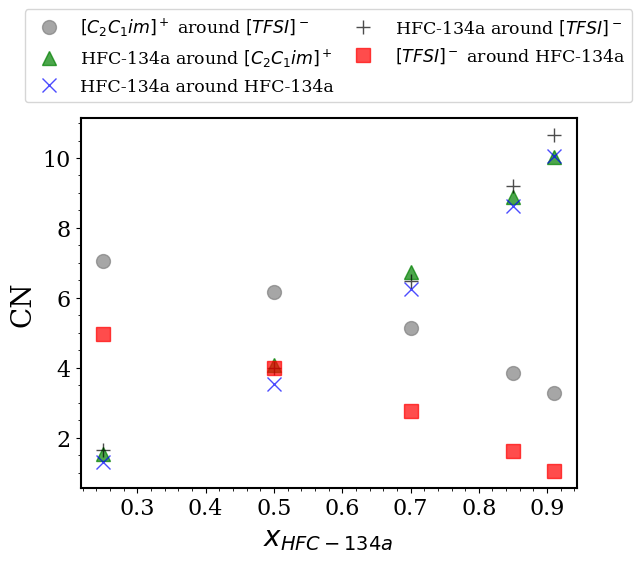

In [20]:

CN_R134a_all = CN_HFC_IL(file_name_R134a, pairs_id, R134a_dist_minima)
CN_R134a = CN_R134a_all[-1]
CN_R134a_names = CN_R134a_all[0][0,:]

CN_R134a_names = np.array([format_label(name) for name in CN_R134a_names])


markers_id = [ 'o', '^', 'x', '+', 's']
color_id = [ 'gray', 'green', 'blue', 'black', 'red']


fig, ax = plt.subplots()
for p in range(len(CN_R134a_names)):
    #print(CN_R134a_names[p])
    plt.plot(comp_array_R134a, CN_R134a[:,p], label=f'{CN_R134a_names[p]}', marker=markers_id[p], \
             linestyle='', markersize=10, alpha=0.7, color=color_id[p])
ax.legend(bbox_to_anchor=(-0.13, 1.02, 1.26, 0.3), loc="lower left", mode="expand", ncol=2, fontsize=12.5)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
ax.minorticks_on()
#plt.ylim(-0.8, 13)
plt.xlabel(r'$x_{HFC-134a}$', fontsize=20)
plt.ylabel(f'CN', fontsize=20)
#plt.title()
#plt.show()
plt.savefig(f"R134a_emimtfsi_CN_n", dpi=300, bbox_inches='tight')


## S(q) plots

In [21]:

file_name_R32_updated = np.concatenate([
    ["pure_emimtfsi_nil_300_100"], 
    file_name_R32, 
    ["R32_noIL_2000_0_1690"]
])
#print(file_name_R32_updated)

file_name_R134a_updated = np.concatenate([
    ["pure_emimtfsi_nil_300_100"], 
    file_name_R134a, 
    ["R134a_noIL_1000_0_665"]
])
#print(file_name_R134a_updated)



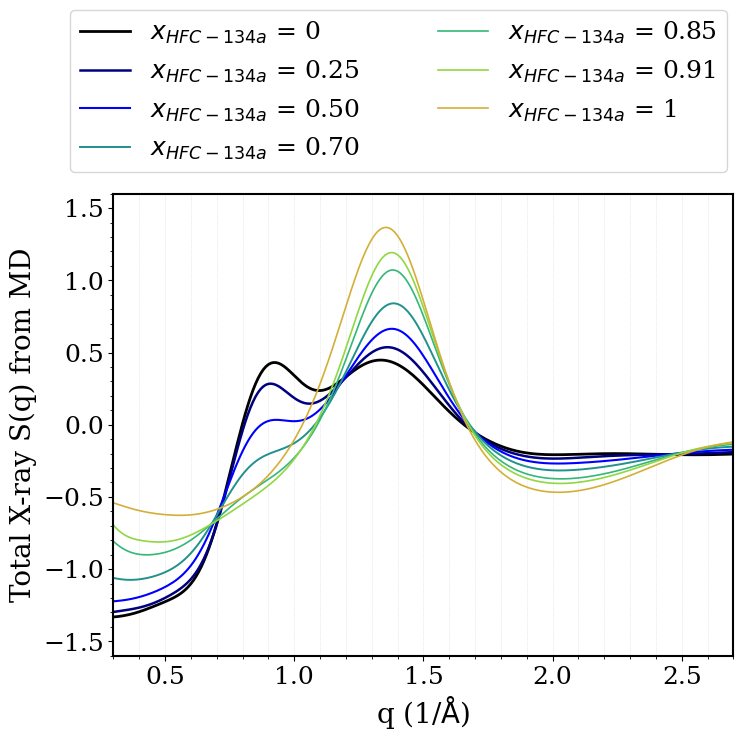

In [22]:

cutoff_index = 270
Sq_R134a = np.zeros([ int(cutoff_index), len(file_name_R134a_updated)])
q_R134a = np.zeros([ int(cutoff_index), len(file_name_R134a_updated)])
for i, name in enumerate(file_name_R134a_updated):
    Sq_dat_all = pd.read_csv(f"{name}_Sq_1.dat", sep=r'\s+', skiprows=1, header=None, engine='python')
    Sq_dat = Sq_dat_all.iloc[0:cutoff_index, 1]
    q_dat = Sq_dat_all.iloc[0:cutoff_index, 0]
    Sq_R134a[:,i] = Sq_dat
    q_R134a[:,i] = q_dat


colors = [
    '#000000', # Black
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
    '#D4AF37' # gold
]


legends_ = [ '$x_{HFC-134a}$ = 0' , '$x_{HFC-134a}$ = 0.25' , '$x_{HFC-134a}$ = 0.50', '$x_{HFC-134a}$ = 0.70',
          '$x_{HFC-134a}$ = 0.85', '$x_{HFC-134a}$ = 0.91', '$x_{HFC-134a}$ = 1' ]

linewidth = [2.0, 1.8, 1.5, 1.4, 1.2, 1.2, 1.2]


plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R134a_updated)):
    ax.plot(q_R134a[:, i], Sq_R134a[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.3, q_R134a[-1, 0]) 
ax.set_ylim(-1.6, 1.6)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=20) 
ax.set_ylabel(r"Total X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R134a_emimtfsi_Sq_n", dpi=300, bbox_inches='tight')
#plt.show()



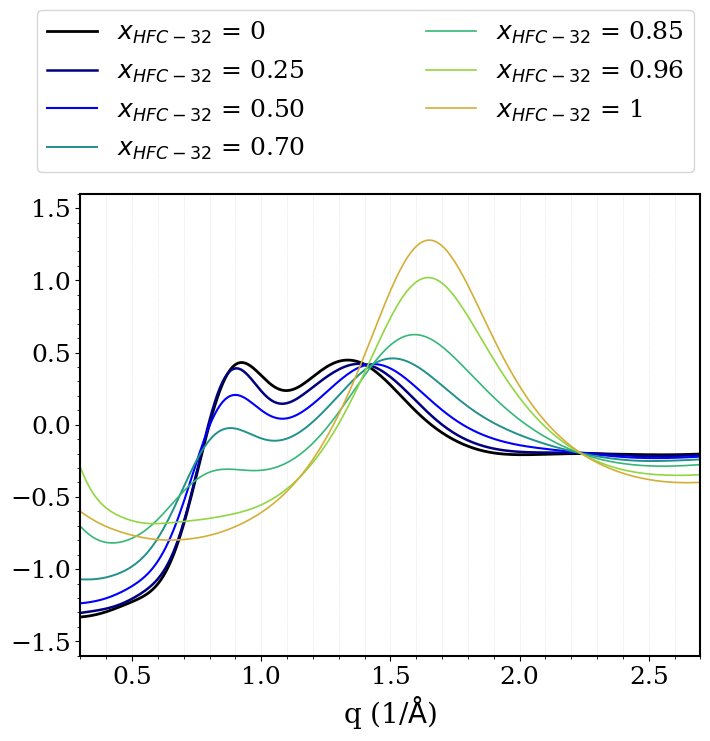

In [23]:

cutoff_index = 270
Sq_R32 = np.zeros([ int(cutoff_index), len(file_name_R32_updated)])
q_R32 = np.zeros([ int(cutoff_index), len(file_name_R32_updated)])
for i, name in enumerate(file_name_R32_updated):
    Sq_dat_all = pd.read_csv(f"{name}_Sq_1.dat", sep=r'\s+', skiprows=1, header=None, engine='python')
    Sq_dat = Sq_dat_all.iloc[0:cutoff_index, 1]
    q_dat = Sq_dat_all.iloc[0:cutoff_index, 0]
    Sq_R32[:,i] = Sq_dat
    q_R32[:,i] = q_dat


colors = [
    '#000000', # Black
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
    '#D4AF37' # gold
]


legends_ = [ '$x_{HFC-32}$ = 0' , '$x_{HFC-32}$ = 0.25' , '$x_{HFC-32}$ = 0.50', '$x_{HFC-32}$ = 0.70',
          '$x_{HFC-32}$ = 0.85', '$x_{HFC-32}$ = 0.96', '$x_{HFC-32}$ = 1' ]

linewidth = [2.0, 1.8, 1.5, 1.4, 1.2, 1.2, 1.2]



plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R32_updated)):
    ax.plot(q_R32[:, i], Sq_R32[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.3, q_R32[-1, 0]) 
ax.set_ylim(-1.6, 1.6)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=20) 
#ax.set_ylabel(r"X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R32_emimtfsi_Sq_n", dpi=300, bbox_inches='tight')
plt.show()



In [24]:

def compute_il_il_sq_R134a(filename):
    Sq_dat_all = pd.read_csv(filename, sep=r'\s+', skiprows=1, header=None, engine='python')
    data = Sq_dat_all.iloc[0:cutoff_index, :]
    data = data.values
    q = data[:, 0]
    c = data
    # ---- full-weight contiguous blocks ----
    full_blocks = (
        np.sum(c[:, 83:95], axis=1) +     # 84–95
        np.sum(c[:, 96:108], axis=1) +    # 97–108
        np.sum(c[:, 109:119], axis=1) +   # 110–119
        np.sum(c[:, 120:129], axis=1) +   # 121–129
        np.sum(c[:, 130:138], axis=1) +   # 131–138
        np.sum(c[:, 139:146], axis=1) +   # 140–146
        np.sum(c[:, 147:153], axis=1) +   # 148–153
        np.sum(c[:, 154:159], axis=1) +   # 155–159
        np.sum(c[:, 160:164], axis=1) +   # 161–164
        np.sum(c[:, 165:168], axis=1) +   # 166–168
        np.sum(c[:, 169:171], axis=1)     # 170–171
    )
    # ---- half-weight columns ----
    half_cols = (
        c[:, 82] +   # 83
        c[:, 95] +   # 96
        c[:, 108] +  # 109
        c[:, 119] +  # 120
        c[:, 129] +  # 130
        c[:, 138] +  # 139
        c[:, 146] +  # 147
        c[:, 153] +  # 154
        c[:, 159] +  # 160
        c[:, 164] +  # 165
        c[:, 168] +  # 169
        c[:, 171] +  # 172
        c[:, 172]    # 173
    ) / 2
    total = 2 * (full_blocks + half_cols)
    return q, total





def compute_il_il_sq_R32(filename):
    Sq_dat_all = pd.read_csv(filename, sep=r'\s+', skiprows=1, header=None, engine='python')
    data = Sq_dat_all.iloc[0:cutoff_index, :]
    data = data.values
    q = data[:, 0]
    c = data
    # ----------------------------
    # Full-weight contiguous blocks
    # ----------------------------
    full_blocks = (
        np.sum(c[:, 48:60], axis=1) +    # 49–60
        np.sum(c[:, 61:72], axis=1) +    # 62–72
        np.sum(c[:, 73:83], axis=1) +    # 74–83
        np.sum(c[:, 84:93], axis=1) +    # 85–93
        np.sum(c[:, 94:102], axis=1) +   # 95–102
        np.sum(c[:, 103:110], axis=1) +  # 104–110
        np.sum(c[:, 111:117], axis=1) +  # 112–117
        np.sum(c[:, 118:123], axis=1) +  # 119–123
        np.sum(c[:, 124:128], axis=1) +  # 125–128
        np.sum(c[:, 129:132], axis=1) +  # 130–132
        np.sum(c[:, 133:135], axis=1) +  # 134–135
        np.sum(c[:, 136:137], axis=1)    # 137
    )
    # ----------------------------
    # Half-weight symmetry columns
    # ----------------------------
    half_cols = (
        c[:, 47] +   # 48
        c[:, 60] +   # 61
        c[:, 72] +   # 73
        c[:, 83] +   # 84
        c[:, 93] +   # 94
        c[:, 102] +  # 103
        c[:, 110] +  # 111
        c[:, 117] +  # 118
        c[:, 123] +  # 124
        c[:, 128] +  # 129
        c[:, 132] +  # 133
        c[:, 135] +  # 136
        c[:, 137]    # 138
    ) / 2
    total = 2 * (full_blocks + half_cols)
    return q, total


def compute_hfc_hfc_sq_R134a(filename):
    Sq_dat_all = pd.read_csv(filename, sep=r'\s+', skiprows=1, header=None, engine='python')
    data = Sq_dat_all.iloc[0:cutoff_index, :]
    data = data.values
    q = data[:, 0]
    c = data
    # ----------------------------
    # Full-weight contiguous blocks
    # ----------------------------
    full_blocks = (
        np.sum(c[:, 3:7], axis=1) +     # 4–7
        np.sum(c[:, 21:24], axis=1) +   # 22–24
        np.sum(c[:, 38:40], axis=1) +   # 39–40
        c[:, 54]                       # 55
     )
     # ---- half-weight symmetry columns ----
    half_cols = (
        c[:, 2] +    # 3
        c[:, 20] +   # 21
        c[:, 37] +   # 38
        c[:, 53] +   # 54
        c[:, 68]     # 69
    ) / 2
    total = 2 * (full_blocks + half_cols)
    return q, total



def compute_hfc_hfc_sq_R32(filename):
    Sq_dat_all = pd.read_csv(filename, sep=r'\s+', skiprows=1, header=None, engine='python')
    data = Sq_dat_all.iloc[0:cutoff_index, :]
    data = data.values
    q = data[:, 0]
    c = data
    # ----------------------------
    # Full-weight contiguous blocks
    # ----------------------------
    full_blocks = (
        np.sum(c[:, 3:5], axis=1) +  # 4–5
        c[:, 19]                    # 20
    )
    # Half-weight columns: 3, 19, 34
    half_cols = (
        c[:, 2] +    # 3
        c[:, 18] +   # 19
        c[:, 33]     # 34
    ) / 2
    total = 2 * (full_blocks + half_cols)
    return q, total




def compute_il_hfc_sq_R134a(filename):
    Sq_dat_all = pd.read_csv(filename, sep=r'\s+', skiprows=1, header=None, engine='python')
    data = Sq_dat_all.iloc[0:cutoff_index, :]
    data = data.values
    q = data[:, 0]
    c = data
    # ----------------------------
    # Full-weight contiguous blocks
    # ----------------------------
    full_sum = (
        np.sum(c[:, 7:20], axis=1) +   # 8–20
        np.sum(c[:, 24:37], axis=1) +  # 25–37
        np.sum(c[:, 40:53], axis=1) +  # 41–53
        np.sum(c[:, 55:68], axis=1) +  # 56–68
        np.sum(c[:, 69:82], axis=1)    # 70–82
    )
    total = 2 * full_sum
    return q, total



def compute_il_hfc_sq_R32(filename):
    Sq_dat_all = pd.read_csv(filename, sep=r'\s+', skiprows=1, header=None, engine='python')
    data = Sq_dat_all.iloc[0:cutoff_index, :]
    data = data.values
    q = data[:, 0]
    c = data
    # ----------------------------
    # Full-weight contiguous blocks
    # ----------------------------
    full_sum = (
        np.sum(c[:, 5:18], axis=1) +   # 6–18
        np.sum(c[:, 20:33], axis=1) +  # 21–33
        np.sum(c[:, 34:47], axis=1)    # 35–47
    )
    total = 2 * full_sum
    return q, total




In [25]:

file_name_R32_mixonly = file_name_R32

file_name_R134a_mixonly = file_name_R134a


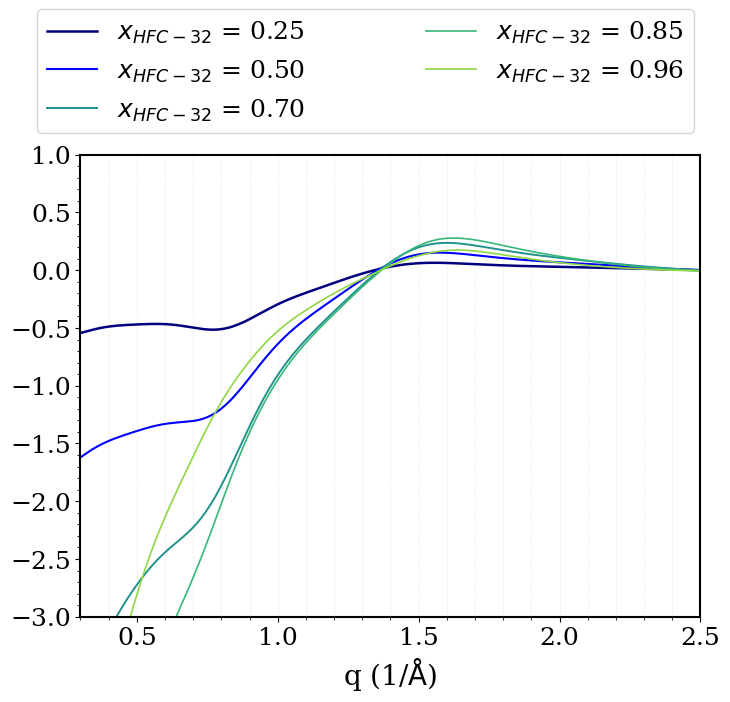

In [27]:
cutoff_index = 250

Sq_R32_mix = np.zeros([ int(cutoff_index), len(file_name_R32_mixonly)])
q_R32_mix = np.zeros([ int(cutoff_index), len(file_name_R32_mixonly)])
for i, name in enumerate(file_name_R32_mixonly):
    filename = f"{name}_Sq_1.dat"
    Sq_dat_all = compute_il_hfc_sq_R32(filename)
    Sq_dat = Sq_dat_all[1]
    q_dat = Sq_dat_all[0]
    Sq_R32_mix[:,i] = Sq_dat
    q_R32_mix[:,i] = q_dat


colors = [
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
]


legends_ = [ '$x_{HFC-32}$ = 0.25' , '$x_{HFC-32}$ = 0.50', '$x_{HFC-32}$ = 0.70',
          '$x_{HFC-32}$ = 0.85', '$x_{HFC-32}$ = 0.96' ]

linewidth = [1.8, 1.5, 1.4, 1.2, 1.2]



plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R32_mixonly)):
    ax.plot(q_R32_mix[:, i], Sq_R32_mix[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.3, q_R32_mix[-1, 0]) 
ax.set_ylim(-3, 1)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=20) 
#ax.set_ylabel(r"X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R32_emimtfsi_Sq_ILHFC", dpi=300, bbox_inches='tight')
#plt.show()


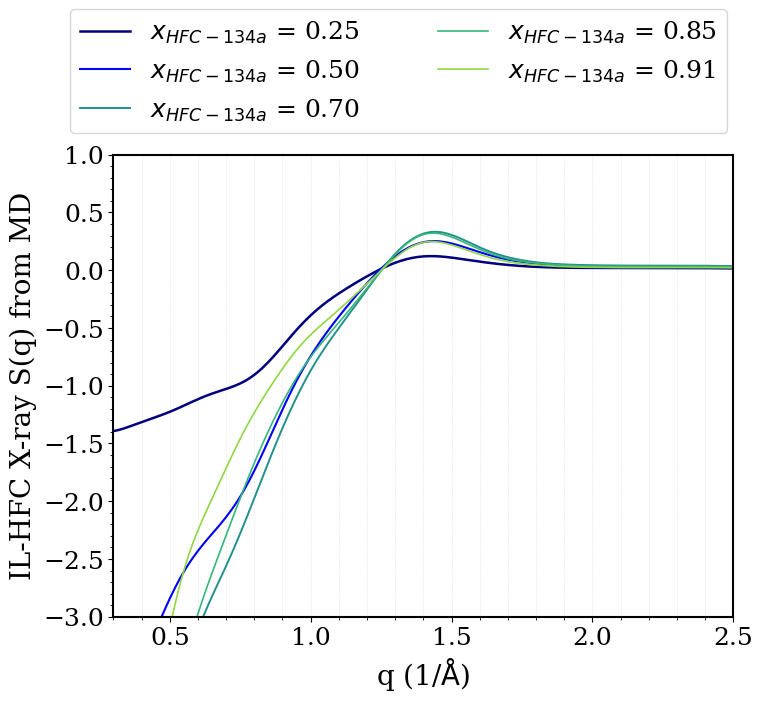

In [28]:

cutoff_index = 250

Sq_R134a_mix = np.zeros([ int(cutoff_index), len(file_name_R134a_mixonly)])
q_R134a_mix = np.zeros([ int(cutoff_index), len(file_name_R134a_mixonly)])
for i, name in enumerate(file_name_R134a_mixonly):
    filename = f"{name}_Sq_1.dat"
    Sq_dat_all = compute_il_hfc_sq_R134a(filename)
    Sq_dat = Sq_dat_all[1]
    q_dat = Sq_dat_all[0]
    Sq_R134a_mix[:,i] = Sq_dat
    q_R134a_mix[:,i] = q_dat


colors = [
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
]


legends_ = [ '$x_{HFC-134a}$ = 0.25' , '$x_{HFC-134a}$ = 0.50', '$x_{HFC-134a}$ = 0.70',
          '$x_{HFC-134a}$ = 0.85', '$x_{HFC-134a}$ = 0.91' ]

linewidth = [1.8, 1.5, 1.4, 1.2, 1.2]



plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R134a_mixonly)):
    ax.plot(q_R134a_mix[:, i], Sq_R134a_mix[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.3, q_R134a_mix[-1, 0]) 
ax.set_ylim(-3, 1)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=20) 
ax.set_ylabel(r"IL-HFC X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R134a_emimtfsi_Sq_ILHFC", dpi=300, bbox_inches='tight')
#plt.show()



In [29]:

file_name_R32_IL = np.concatenate([
    ["pure_emimtfsi_nil_300_100"], 
    file_name_R32
])


file_name_R134a_IL = np.concatenate([
    ["pure_emimtfsi_nil_300_100"], 
    file_name_R134a
])


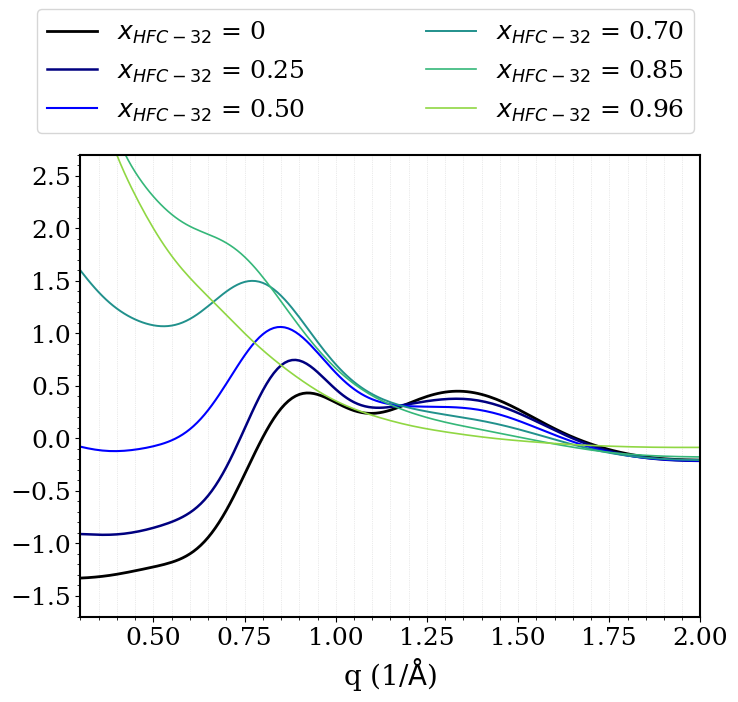

In [30]:
cutoff_index = 200

Sq_R32_ILIL = np.zeros([ int(cutoff_index), len(file_name_R32_IL)])
q_R32_ILIL = np.zeros([ int(cutoff_index), len(file_name_R32_IL)])
for i, name in enumerate(file_name_R32_IL):
    filename = f"{name}_Sq_1.dat"
    if i==0:
        Sq_dat_all = pd.read_csv(f"{name}_Sq_1.dat", sep=r'\s+', skiprows=1, header=None, engine='python')
        Sq_dat = Sq_dat_all.iloc[0:cutoff_index, 1]
        q_dat = Sq_dat_all.iloc[0:cutoff_index, 0]
    else:
        Sq_dat_all = compute_il_il_sq_R32(filename)
        Sq_dat = Sq_dat_all[1]
        q_dat = Sq_dat_all[0]
    Sq_R32_ILIL[:,i] = Sq_dat
    q_R32_ILIL[:,i] = q_dat


colors = [
    '#000000', # Black
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
]


legends_ = [ '$x_{HFC-32}$ = 0' , '$x_{HFC-32}$ = 0.25' , '$x_{HFC-32}$ = 0.50', '$x_{HFC-32}$ = 0.70',
          '$x_{HFC-32}$ = 0.85', '$x_{HFC-32}$ = 0.96' ]

linewidth = [2.0, 1.8, 1.5, 1.4, 1.2, 1.2]



plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R32_IL)):
    ax.plot(q_R32_ILIL[:, i], Sq_R32_ILIL[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.3, q_R32_ILIL[-1, 0]) 
ax.set_ylim(-1.7, 2.7)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=20) 
#ax.set_ylabel(r"X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R32_emimtfsi_Sq_ILIL", dpi=300, bbox_inches='tight')
#plt.show()


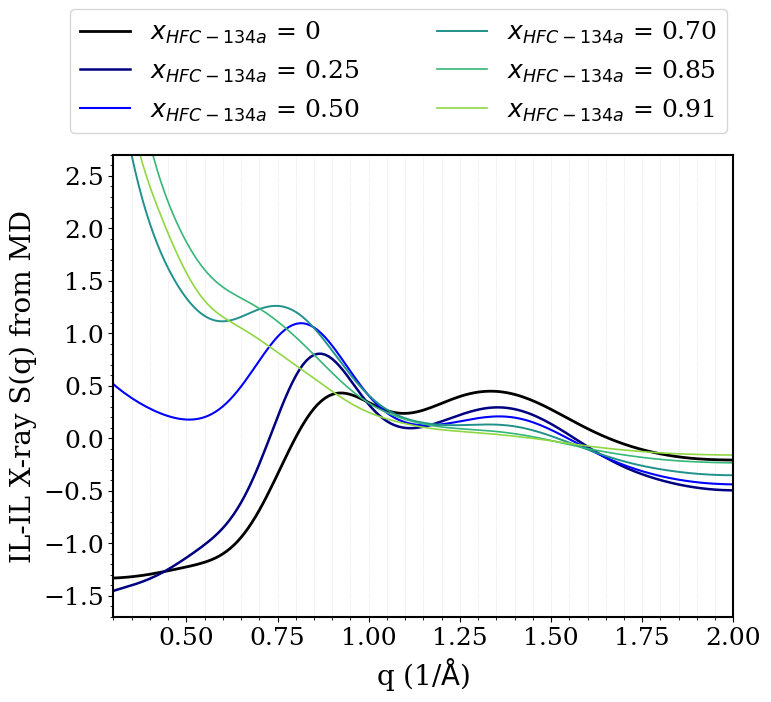

In [31]:

cutoff_index = 200

Sq_R134a_ILIL = np.zeros([ int(cutoff_index), len(file_name_R134a_IL)])
q_R134a_ILIL = np.zeros([ int(cutoff_index), len(file_name_R134a_IL)])
for i, name in enumerate(file_name_R134a_IL):
    filename = f"{name}_Sq_1.dat"
    if i==0:
        Sq_dat_all = pd.read_csv(f"{name}_Sq_1.dat", sep=r'\s+', skiprows=1, header=None, engine='python')
        Sq_dat = Sq_dat_all.iloc[0:cutoff_index, 1]
        q_dat = Sq_dat_all.iloc[0:cutoff_index, 0]
    else:
        Sq_dat_all = compute_il_il_sq_R134a(filename)
        Sq_dat = Sq_dat_all[1]
        q_dat = Sq_dat_all[0]
    Sq_R134a_ILIL[:,i] = Sq_dat
    q_R134a_ILIL[:,i] = q_dat


colors = [
    '#000000', # Black
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
]


legends_ = [ '$x_{HFC-134a}$ = 0' , '$x_{HFC-134a}$ = 0.25' , '$x_{HFC-134a}$ = 0.50', '$x_{HFC-134a}$ = 0.70',
          '$x_{HFC-134a}$ = 0.85', '$x_{HFC-134a}$ = 0.91' ]

linewidth = [2.0, 1.8, 1.5, 1.4, 1.2, 1.2]



plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R134a_IL)):
    ax.plot(q_R134a_ILIL[:, i], Sq_R134a_ILIL[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.3, q_R134a_ILIL[-1, 0]) 
ax.set_ylim(-1.7, 2.7)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=20) 
ax.set_ylabel(r"IL-IL X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R134a_emimtfsi_Sq_ILIL", dpi=300, bbox_inches='tight')
#plt.show()


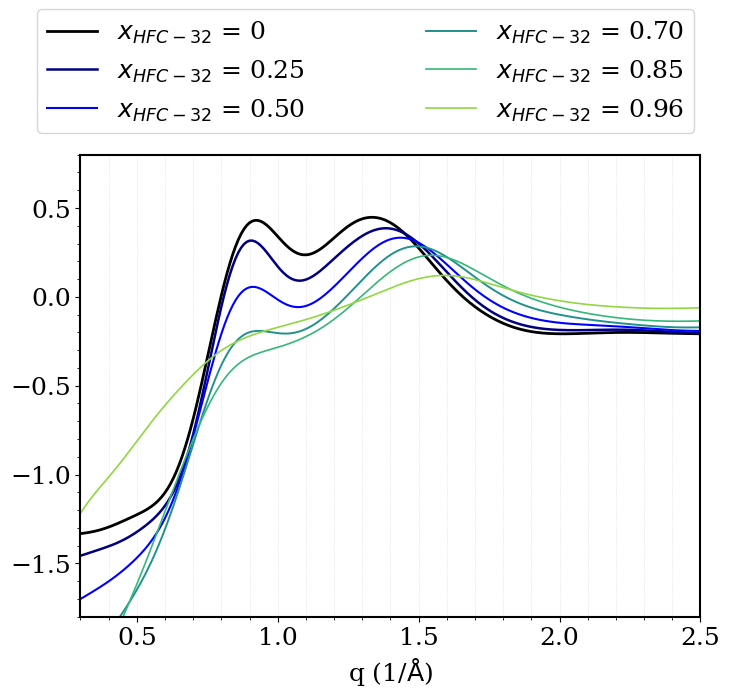

In [32]:
cutoff_index = 250

Sq_R32_ILILHFC = np.zeros([ int(cutoff_index), len(file_name_R32_IL)])
q_R32_ILILHFC = np.zeros([ int(cutoff_index), len(file_name_R32_IL)])
for i, name in enumerate(file_name_R32_IL):
    filename = f"{name}_Sq_1.dat"
    if i==0:
        Sq_dat_all = pd.read_csv(f"{name}_Sq_1.dat", sep=r'\s+', skiprows=1, header=None, engine='python')
        Sq_dat = Sq_dat_all.iloc[0:cutoff_index, 1]
        q_dat = Sq_dat_all.iloc[0:cutoff_index, 0]
    else:
        Sq_dat_all_ilil = compute_il_il_sq_R32(filename)
        Sq_dat_all_ilhfc = compute_il_hfc_sq_R32(filename)
        Sq_dat = Sq_dat_all_ilil[1] + Sq_dat_all_ilhfc[1]
        q_dat = Sq_dat_all_ilil[0]
    Sq_R32_ILILHFC[:,i] = Sq_dat
    q_R32_ILILHFC[:,i] = q_dat


colors = [
    '#000000', # Black
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
]


legends_ = [ '$x_{HFC-32}$ = 0' , '$x_{HFC-32}$ = 0.25' , '$x_{HFC-32}$ = 0.50', '$x_{HFC-32}$ = 0.70',
          '$x_{HFC-32}$ = 0.85', '$x_{HFC-32}$ = 0.96' ]

linewidth = [2.0, 1.8, 1.5, 1.4, 1.2, 1.2]



plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R32_IL)):
    ax.plot(q_R32_ILILHFC[:, i], Sq_R32_ILILHFC[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.3, q_R32_ILILHFC[-1, 0]) 
ax.set_ylim(-1.8, 0.8)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=18) 
#ax.set_ylabel(r"X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R32_emimtfsi_Sq_ILILHFC", dpi=300, bbox_inches='tight')
#plt.show()


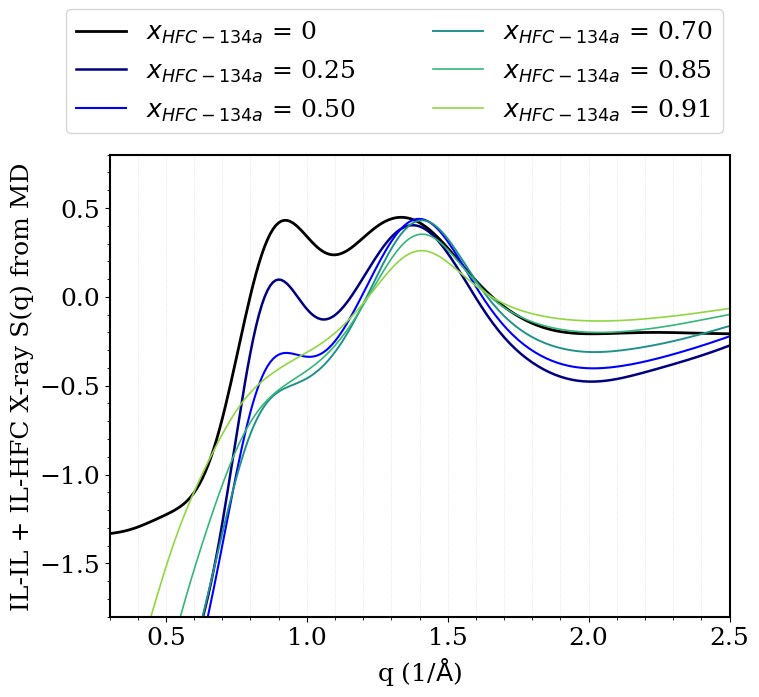

In [33]:

cutoff_index = 250

Sq_R134a_ILILHFC = np.zeros([ int(cutoff_index), len(file_name_R134a_IL)])
q_R134a_ILILHFC = np.zeros([ int(cutoff_index), len(file_name_R134a_IL)])
for i, name in enumerate(file_name_R134a_IL):
    filename = f"{name}_Sq_1.dat"
    if i==0:
        Sq_dat_all = pd.read_csv(f"{name}_Sq_1.dat", sep=r'\s+', skiprows=1, header=None, engine='python')
        Sq_dat = Sq_dat_all.iloc[0:cutoff_index, 1]
        q_dat = Sq_dat_all.iloc[0:cutoff_index, 0]
    else:
        Sq_dat_all_ilil = compute_il_il_sq_R134a(filename)
        Sq_dat_all_ilhfc = compute_il_hfc_sq_R134a(filename)
        Sq_dat = Sq_dat_all_ilil[1] + Sq_dat_all_ilhfc[1]
        q_dat = Sq_dat_all_ilil[0]
    Sq_R134a_ILILHFC[:,i] = Sq_dat
    q_R134a_ILILHFC[:,i] = q_dat


colors = [
    '#000000', # Black
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
]


legends_ = [ '$x_{HFC-134a}$ = 0' , '$x_{HFC-134a}$ = 0.25' , '$x_{HFC-134a}$ = 0.50', '$x_{HFC-134a}$ = 0.70',
          '$x_{HFC-134a}$ = 0.85', '$x_{HFC-134a}$ = 0.91' ]

linewidth = [2.0, 1.8, 1.5, 1.4, 1.2, 1.2]



plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R134a_IL)):
    ax.plot(q_R134a_ILILHFC[:, i], Sq_R134a_ILILHFC[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.3, q_R134a_ILILHFC[-1, 0]) 
ax.set_ylim(-1.8, 0.8)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=18) 
ax.set_ylabel(r"IL-IL + IL-HFC X-ray S(q) from MD", fontsize=18)

plt.savefig(f"R134a_emimtfsi_Sq_ILILHFC", dpi=300, bbox_inches='tight')
#plt.show()


In [34]:

file_name_R32_R32 = np.concatenate([
    file_name_R32, 
    ["R32_noIL_2000_0_1690"]
])


file_name_R134a_R134a = np.concatenate([
    file_name_R134a, 
    ["R134a_noIL_1000_0_665"]
])


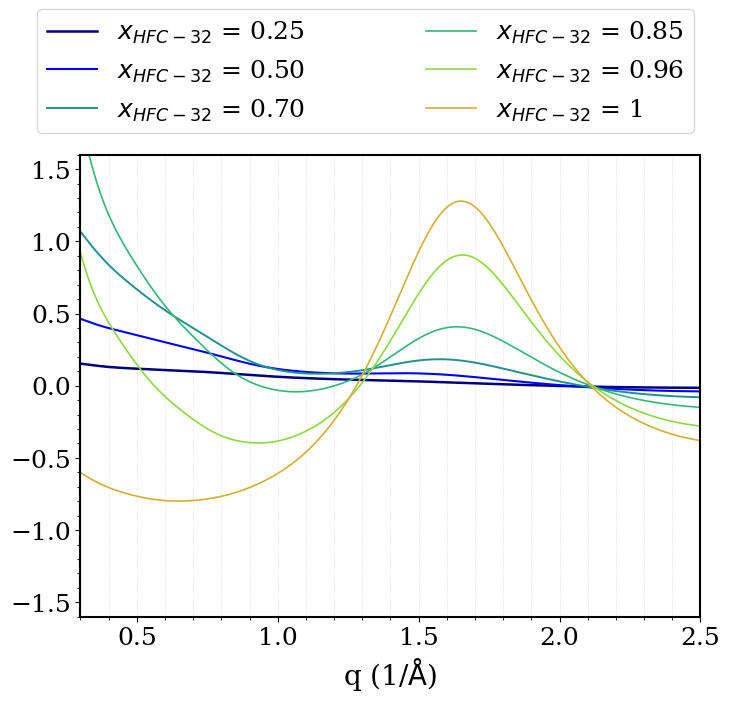

In [35]:
cutoff_index = 250

Sq_R32_R32 = np.zeros([ int(cutoff_index), len(file_name_R32_R32)])
q_R32_R32 = np.zeros([ int(cutoff_index), len(file_name_R32_R32)])
for i, name in enumerate(file_name_R32_R32):
    filename = f"{name}_Sq_1.dat"
    if i==(len(file_name_R32_R32) - 1):
        Sq_dat_all = pd.read_csv(f"{name}_Sq_1.dat", sep=r'\s+', skiprows=1, header=None, engine='python')
        Sq_dat = Sq_dat_all.iloc[0:cutoff_index, 1]
        q_dat = Sq_dat_all.iloc[0:cutoff_index, 0]
    else:
        Sq_dat_all = compute_hfc_hfc_sq_R32(filename)
        Sq_dat = Sq_dat_all[1]
        q_dat = Sq_dat_all[0]
    Sq_R32_R32[:,i] = Sq_dat
    q_R32_R32[:,i] = q_dat


colors = [
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
    '#D4AF37' # gold
]


legends_ = [ '$x_{HFC-32}$ = 0.25' , '$x_{HFC-32}$ = 0.50', '$x_{HFC-32}$ = 0.70',
          '$x_{HFC-32}$ = 0.85', '$x_{HFC-32}$ = 0.96', '$x_{HFC-32}$ = 1' ]

linewidth = [ 1.8, 1.5, 1.4, 1.2, 1.2, 1.2]



plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R32_R32)):
    ax.plot(q_R32_R32[:, i], Sq_R32_R32[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.3, q_R32_R32[-1, 0]) 
ax.set_ylim(-1.6, 1.6)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=20) 
#ax.set_ylabel(r"X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R32_emimtfsi_Sq_HFCHFC", dpi=300, bbox_inches='tight')
#plt.show()


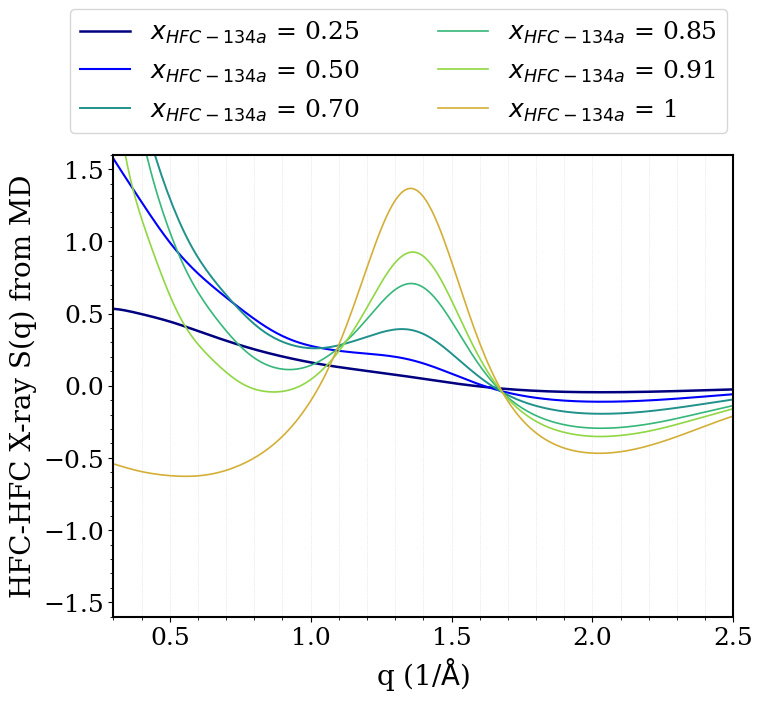

In [36]:
cutoff_index = 250

Sq_R134a_R134a = np.zeros([ int(cutoff_index), len(file_name_R134a_R134a)])
q_R134a_R134a = np.zeros([ int(cutoff_index), len(file_name_R134a_R134a)])
for i, name in enumerate(file_name_R134a_R134a):
    filename = f"{name}_Sq_1.dat"
    if i==(len(file_name_R134a_R134a) - 1):
        Sq_dat_all = pd.read_csv(f"{name}_Sq_1.dat", sep=r'\s+', skiprows=1, header=None, engine='python')
        Sq_dat = Sq_dat_all.iloc[0:cutoff_index, 1]
        q_dat = Sq_dat_all.iloc[0:cutoff_index, 0]
    else:
        Sq_dat_all = compute_hfc_hfc_sq_R134a(filename)
        Sq_dat = Sq_dat_all[1]
        q_dat = Sq_dat_all[0]
    Sq_R134a_R134a[:,i] = Sq_dat
    q_R134a_R134a[:,i] = q_dat


colors = [
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
    '#D4AF37' # gold
]


legends_ = [ '$x_{HFC-134a}$ = 0.25' , '$x_{HFC-134a}$ = 0.50', '$x_{HFC-134a}$ = 0.70',
          '$x_{HFC-134a}$ = 0.85', '$x_{HFC-134a}$ = 0.91', '$x_{HFC-134a}$ = 1' ]

linewidth = [ 1.8, 1.5, 1.4, 1.2, 1.2, 1.2]



plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6)) # Recommended to use ax for better control

for i in range(len(file_name_R134a_R134a)):
    ax.plot(q_R134a_R134a[:, i], Sq_R134a_R134a[:, i], color=colors[i], label=legends_[i], linewidth=linewidth[i])


ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.3, q_R134a_R134a[-1, 0]) 
ax.set_ylim(-1.6, 1.6)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=20) 
ax.set_ylabel(r"HFC-HFC X-ray S(q) from MD", fontsize=20)

plt.savefig(f"R134a_emimtfsi_Sq_HFCHFC", dpi=300, bbox_inches='tight')
#plt.show()


In [37]:
exp_Sq_data_file = pd.read_excel("SWAXS_tot_plot.xlsx")

In [38]:
exp_Sq_data_file.head()

,HFC Pct,q(A-1)_0,I_subtracted(mm-1),I_offset_0,HFC Pct.1,q(A-1)_1,I_subtracted(mm-1).1,I_offset_1,HFC Pct.2,q(A-1)_2,...,I_subtracted(mm-1).3,I_offset_3,HFC Pct.4,q(A-1)_4,I_subtracted(mm-1).4,I_offset_4,HFC Pct.5,q(A-1)_5,I_subtracted(mm-1).5,I_offset_5
0,0,0.238040,0.001751,0.010503,18,0.238040,0.001350,0.006748,35,0.238040,...,0.003700,0.011101,82,0.238040,0.003024,0.018142,88,0.238040,0.003071,0.009212
1,0,0.243917,0.002058,0.012345,18,0.243917,0.002383,0.011914,35,0.243917,...,0.004836,0.014507,82,0.243917,0.003162,0.018972,88,0.243917,0.003412,0.010236
2,0,0.249795,0.001941,0.011643,18,0.249795,0.002479,0.012396,35,0.249795,...,0.004939,0.014816,82,0.249795,0.003181,0.019085,88,0.249795,0.003488,0.010465
3,0,0.255672,0.002137,0.012823,18,0.255672,0.002409,0.012046,35,0.255672,...,0.004803,0.014408,82,0.255672,0.003171,0.019025,88,0.255672,0.003268,0.009805
4,0,0.261550,0.002383,0.014299,18,0.261550,0.002383,0.011916,35,0.261550,...,0.004902,0.014707,82,0.261550,0.003162,0.018969,88,0.261550,0.003270,0.009809


In [39]:

# Exp_q_labels = ["q(A-1)_0", "q(A-1)_1", "q(A-1)_2", "q(A-1)_3", "q(A-1)_4", "q(A-1)_5"]
# Exp_I_labels = ["I_offset_0", "I_offset_1", "I_offset_2", "I_offset_3", "I_offset_4", "I_offset_5"]
# Exp_comp_labels = np.array([0, 18, 35, 60, 82, 88])/100


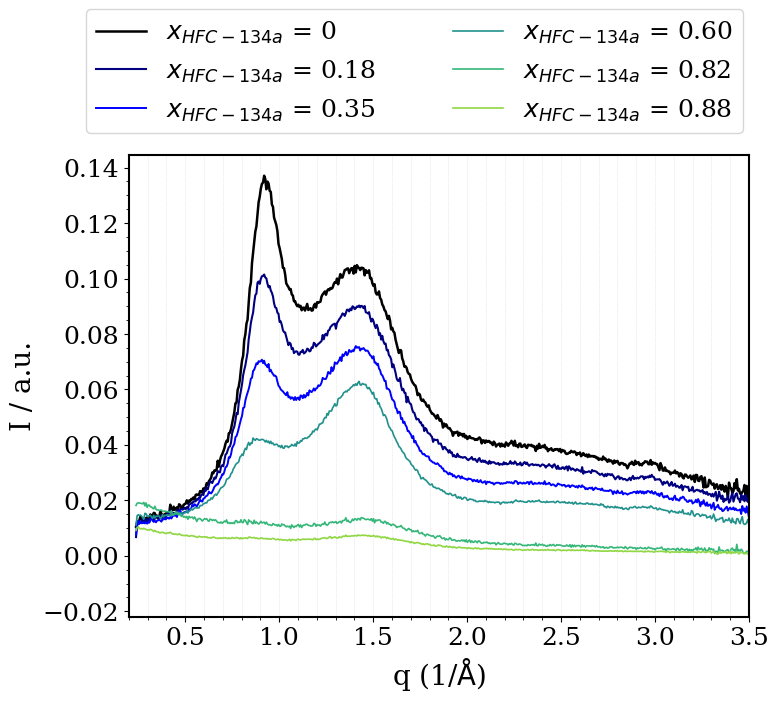

In [40]:

tags = ["0", "1", "2", "3", "4", "5"]

colors = [
    '#000000', # Black
    '#000080', # Midnight blue
    '#0000FF', # Blue
    '#21918c', # Teal
    '#35b779', # Green
    '#90d743', # Light Green
]


legends_ = [ '$x_{HFC-134a}$ = 0' , '$x_{HFC-134a}$ = 0.18', '$x_{HFC-134a}$ = 0.35',
          '$x_{HFC-134a}$ = 0.60', '$x_{HFC-134a}$ = 0.82', '$x_{HFC-134a}$ = 0.88' ]


linewidth = [ 1.8, 1.5, 1.4, 1.2, 1.2, 1.2]


plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 18,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots(figsize=(8, 6))



for i, tag in enumerate(tags):
    Exp_q = exp_Sq_data_file[f"q(A-1)_{tag}"]
    Exp_I = exp_Sq_data_file[f"I_offset_{tag}"]
    ax.plot(Exp_q, Exp_I, color=colors[i], label=legends_[i], linewidth=linewidth[i])



ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())


ax.grid(visible=True, which='both', axis='x', linestyle=':', linewidth=0.5, alpha=0.5)

# --- Styling and Labels ---
ax.tick_params(axis='both', which='major', labelsize=18)
ax.set_xlim(0.2, 3.5) 
# ax.set_ylim(-1.6, 1.6)

# Legend and Labels
ax.legend(bbox_to_anchor=(-0.09, 1.02, 1.1, 0.3), loc="lower left", 
           mode="expand", ncol=2, fontsize=18)
ax.set_xlabel(r"q (1/$\mathrm{\AA}$)", fontsize=20) 
ax.set_ylabel(r"I / a.u.", fontsize=20)

plt.savefig(f"R134a_emimtfsi_Iq_tot_Exp_New", dpi=300, bbox_inches='tight')



In [2]:
# Sq_check_R32 = pd.read_csv(
#     "R32_emimtfsi_2048_86_1653_Sq_1.dat", 
#     sep=r'\s+', 
#     skiprows=1,      # Skip the header line manually
#     header=None, 
#     engine='python'  # The Python engine is more robust for regex and whitespace
# )

In [3]:
#Sq_check_R32.head()

In [4]:
# Sq_check_R134a = pd.read_csv(
#     "R134a_emimtfsi_1088_192_646_Sq_1.dat", 
#     sep=r'\s+', 
#     skiprows=1,      # Skip the header line manually
#     header=None, 
#     engine='python'  # The Python engine is more robust for regex and whitespace
# )

In [5]:
#Sq_check_R134a.head()